Using Colab cache for faster access to the 'deepglobe-road-extraction-dataset' dataset.
Using Colab cache for faster access to the 'deepglobe-land-cover-classification-dataset' dataset.
gdown failed: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'A
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
using zip from Drive: /content/drive/MyDrive/data_original_size_v1.zip
roads: 6226 | urban: 803 | ttpla: 1242
TTPLA labels: {'cable'}
roads: train (300, 256), test (100, 256), positives(train)=150
urban: train (300, 256), test (100, 256), positives(train)=150
wires: train (300, 256), test (100, 256), positives(train)=150

=== roads ===
  step   0  loss 0.681
  step  10  loss 0.571
  step  20  loss 0.665
  step  30  loss 0.535
  step  40  loss 0.664
  step  50  loss 0.624

=== urban ===
  step   0  loss 0.712
  step  10  loss 0.686
  step  20  l

,task,QCNN acc,LogReg acc,MLP acc,QCNN params,LogReg params,MLP params,flagged %,QCNN acc (confident only)
0,roads,0.68,0.65,0.69,21,9,161,53.0,0.787
1,urban,0.62,0.66,0.62,21,9,161,41.0,0.661
2,wires,0.59,0.49,0.61,21,9,161,90.0,0.600


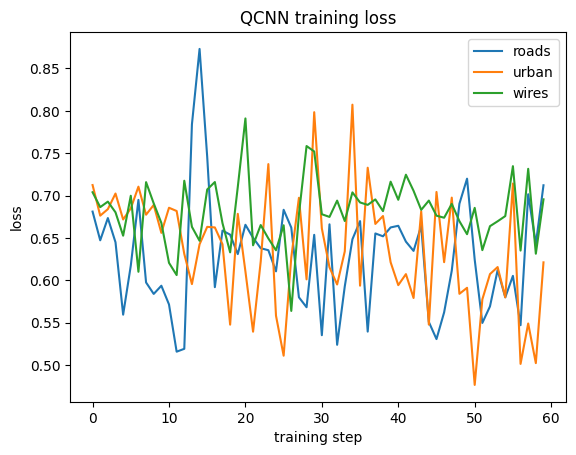

In [20]:
!pip install pennylane kagglehub gdown -q

import kagglehub, gdown, glob, os, zipfile, json
import numpy as np
from PIL import Image, ImageDraw

# ============ 1. DOWNLOAD DATA ============
road = kagglehub.dataset_download("balraj98/deepglobe-road-extraction-dataset")
land = kagglehub.dataset_download("balraj98/deepglobe-land-cover-classification-dataset")

# ---- TTPLA zip: (a) Drive link, (b) any zip in your Drive that contains .json files ----
ZIP = "ttpla_subset.zip"
def ok(p): return os.path.exists(p) and zipfile.is_zipfile(p)

if not ok(ZIP):
    try:
        gdown.download(id="1VHtu_ndp3arjMpyeAMtegSCux_21Qp7N", output=ZIP, quiet=False)
    except Exception as e:
        print("gdown failed:", str(e)[:120])

if not ok(ZIP):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        cands = glob.glob("/content/drive/MyDrive/*.zip") + glob.glob("/content/drive/MyDrive/*/*.zip")
        for c in cands:
            try:
                with zipfile.ZipFile(c) as z:
                    names = z.namelist()
                if any(n.lower().endswith(".json") for n in names) and any(n.lower().endswith(".jpg") for n in names):
                    print("using zip from Drive:", c); ZIP = c; break
            except Exception:
                pass
    except Exception as e:
        print("Drive step failed:", str(e)[:120])

os.makedirs("/content/ttpla", exist_ok=True)
if ok(ZIP):
    with zipfile.ZipFile(ZIP) as z: z.extractall("/content/ttpla")
else:
    print("!! TTPLA zip not available -> wires task will be skipped")

road_files = [f for f in sorted(glob.glob(f"{road}/**/*_sat.jpg", recursive=True))
              if os.path.exists(f.replace("_sat.jpg", "_mask.png"))]
land_files = [f for f in sorted(glob.glob(f"{land}/**/*_sat.jpg", recursive=True))
              if os.path.exists(f.replace("_sat.jpg", "_mask.png"))]
tt_files = [f for f in sorted(glob.glob("/content/ttpla/**/*", recursive=True))
            if f.lower().endswith((".jpg", ".jpeg"))
            and os.path.exists(os.path.splitext(f)[0] + ".json")]
print("roads:", len(road_files), "| urban:", len(land_files), "| ttpla:", len(tt_files))
if tt_files:
    m = json.load(open(os.path.splitext(tt_files[0])[0] + ".json"))
    print("TTPLA labels:", {s["label"] for s in m["shapes"]})

# ============ 2. LOADERS + PATCH BUILDER ============
def load_road(sat):                      # white = road
    g = Image.open(sat).convert("L").resize((512, 512))
    m = Image.open(sat.replace("_sat.jpg", "_mask.png")).convert("L").resize((512, 512), Image.NEAREST)
    return np.array(g), np.array(m) > 127

def load_urban(sat):                     # urban = cyan (0,255,255)
    g = Image.open(sat).convert("L").resize((612, 612))
    m = np.array(Image.open(sat.replace("_sat.jpg", "_mask.png")).convert("RGB")
                 .resize((612, 612), Image.NEAREST))
    return np.array(g), (m[..., 0] < 128) & (m[..., 1] > 128) & (m[..., 2] > 128)

CABLE_KEYS = ("cable", "wire", "line")
def load_ttpla(jpg, scale=2):
    meta = json.load(open(os.path.splitext(jpg)[0] + ".json"))
    img = Image.open(jpg).convert("L"); W, H = img.size
    img = img.resize((W // scale, H // scale))
    mk = Image.new("L", img.size, 0); d = ImageDraw.Draw(mk)
    for s in meta["shapes"]:
        if any(k in s["label"].lower() for k in CABLE_KEYS) and len(s["points"]) >= 3:
            d.polygon([(x / scale, y / scale) for x, y in s["points"]], fill=1)
    return np.array(img), np.array(mk) > 0

def feat_vec(p, feat):
    p = p.astype(np.float32) / 255.0
    if feat == "edge":                   # edges keep thin wires visible
        gy, gx = np.gradient(p); p = np.clip(np.hypot(gx, gy) * 4, 0, 1)
    small = Image.fromarray((p * 255).astype(np.uint8)).resize((16, 16), Image.BOX)
    return (np.array(small) / 255.0).ravel()

def patches_from_files(files, loader, patch, thr, feat):
    pos, neg = [], []
    for f in files:
        g, m = loader(f)
        for y in range(0, g.shape[0] - patch + 1, patch):
            for x in range(0, g.shape[1] - patch + 1, patch):
                frac = m[y:y+patch, x:x+patch].mean()
                if frac >= thr:   pos.append(feat_vec(g[y:y+patch, x:x+patch], feat))
                elif frac == 0:   neg.append(feat_vec(g[y:y+patch, x:x+patch], feat))
    return pos, neg

def balance(pos, neg, n, rng):
    n = min(n, len(pos), len(neg))
    if n == 0: return None, None
    pi = rng.choice(len(pos), n, replace=False); ni = rng.choice(len(neg), n, replace=False)
    X = np.array([pos[i] for i in pi] + [neg[i] for i in ni]); y = np.array([1]*n + [0]*n)
    k = rng.permutation(len(X)); return X[k], y[k]

def make_dataset(files, loader, patch, thr, feat, n_tr=150, n_te=50, seed=0):
    rng = np.random.default_rng(seed)           # split BY IMAGE (no leakage)
    files = list(files); rng.shuffle(files)
    k = max(1, int(0.75 * len(files)))
    Xtr, ytr = balance(*patches_from_files(files[:k], loader, patch, thr, feat), n_tr, rng)
    Xte, yte = balance(*patches_from_files(files[k:], loader, patch, thr, feat), n_te, rng)
    return Xtr, ytr, Xte, yte

# ============ 3. BUILD THE 3 DATASETS ============
CFG = {
  "roads": dict(files=road_files[:40],  loader=load_road,  patch=64, thr=0.05, feat="raw"),
  "urban": dict(files=land_files[:150], loader=load_urban, patch=64, thr=0.50, feat="raw"),
  "wires": dict(files=tt_files[:60],    loader=load_ttpla, patch=64, thr=0.02, feat="edge"),
}
RAW = {}
for name, c in CFG.items():
    if len(c["files"]) < 2:
        print(f"[skip] {name}: not enough files found"); continue
    out = make_dataset(**c)
    if out[0] is None or out[2] is None:
        print(f"[skip] {name}: could not find both classes (check labels / thresholds)"); continue
    RAW[name] = out
    print(f"{name}: train {out[0].shape}, test {out[2].shape}, positives(train)={out[1].sum()}")

# ============ 4. QCNN ============
import torch, pennylane as qml
n = 8
dev = qml.device("default.qubit", wires=n)

def conv(p, a, b):
    qml.RY(p[0], wires=a); qml.RY(p[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RZ(p[2], wires=b); qml.CNOT(wires=[b, a])
    qml.RY(p[3], wires=a); qml.RY(p[4], wires=b)

def pool(p, a, b):                        # a discarded, b kept
    qml.CRZ(p[0], wires=[a, b]); qml.PauliX(wires=a); qml.CRX(p[1], wires=[a, b])

@qml.qnode(dev, interface="torch")
def qcnn(x, w, pw):
    qml.AngleEmbedding(x, wires=range(n), rotation="Y")     # angle encoding
    wires, layer = list(range(n)), 0
    while len(wires) > 1:
        for i in range(0, len(wires) - 1, 2): conv(w[layer], wires[i], wires[i + 1])
        for i in range(0, len(wires) - 1, 2): pool(pw[layer], wires[i], wires[i + 1])
        wires = wires[1::2]; layer += 1
    return qml.expval(qml.PauliZ(wires[0]))

def predict_prob(X, w, pw):
    with torch.no_grad():
        return ((qcnn(X, w, pw) + 1) / 2).numpy()

def train_qcnn(Xtr, ytr, Xte, steps=60, bs=32, lr=0.1, seed=0):
    torch.manual_seed(seed)
    w  = (0.5 * torch.randn(3, 5, dtype=torch.float64)).requires_grad_()
    pw = (0.5 * torch.randn(3, 2, dtype=torch.float64)).requires_grad_()
    opt = torch.optim.Adam([w, pw], lr=lr)
    Xt = torch.tensor(Xtr, dtype=torch.float64); yt = torch.tensor(ytr, dtype=torch.float64)
    hist = []
    for s in range(steps):
        idx = torch.randperm(len(Xt))[:bs]
        prob = ((qcnn(Xt[idx], w, pw) + 1) / 2).clamp(1e-5, 1 - 1e-5)
        loss = torch.nn.functional.binary_cross_entropy(prob, yt[idx])
        opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
        if s % 10 == 0: print(f"  step {s:3d}  loss {loss.item():.3f}")
    ptr = predict_prob(Xt, w, pw)
    pte = predict_prob(torch.tensor(Xte, dtype=torch.float64), w, pw)
    return ptr, pte, hist, w.numel() + pw.numel()

# ============ 5. RUN: QCNN vs CLASSICAL + CONFIDENCE ============
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

rows, curves = [], {}
for name, (Xtr, ytr, Xte, yte) in RAW.items():
    print(f"\n=== {name} ===")
    pca = PCA(8).fit(Xtr)                                    # fit on TRAIN only
    sc = MinMaxScaler((0, np.pi)).fit(pca.transform(Xtr))
    Ftr = np.clip(sc.transform(pca.transform(Xtr)), 0, np.pi)
    Fte = np.clip(sc.transform(pca.transform(Xte)), 0, np.pi)

    ptr, pte, hist, nq = train_qcnn(Ftr, ytr, Fte)
    q_acc = ((pte > 0.5) == yte).mean()

    lr_ = LogisticRegression(max_iter=1000).fit(Ftr, ytr); lr_acc = lr_.score(Fte, yte)
    mlp = MLPClassifier((16,), max_iter=2000, random_state=0).fit(Ftr, ytr); mlp_acc = mlp.score(Fte, yte)

    conf = np.abs(pte - 0.5) * 2          # decision support: low confidence -> manual check
    flag = conf < 0.2
    conf_acc = ((pte[~flag] > 0.5) == yte[~flag]).mean() if (~flag).any() else np.nan

    rows.append({"task": name, "QCNN acc": round(q_acc, 3), "LogReg acc": round(lr_acc, 3),
                 "MLP acc": round(mlp_acc, 3), "QCNN params": nq, "LogReg params": 9,
                 "MLP params": 8*16 + 16 + 16 + 1, "flagged %": round(100 * flag.mean(), 1),
                 "QCNN acc (confident only)": round(conf_acc, 3)})
    curves[name] = hist

results = pd.DataFrame(rows)
print("\n"); display(results)
results.to_csv("results.csv", index=False)

for k, h in curves.items(): plt.plot(h, label=k)
plt.xlabel("training step"); plt.ylabel("loss"); plt.title("QCNN training loss"); plt.legend(); plt.show()

wires: (400, 8) (200, 8)

=== roads ===
  step   0  loss 0.682
  step  10  loss 0.593
  step  20  loss 0.675
  step  30  loss 0.584
  step  40  loss 0.639
  step  50  loss 0.617
  step  60  loss 0.599
  step  70  loss 0.680
  step  80  loss 0.566
  step  90  loss 0.638
  seed 0: acc 0.650
  step   0  loss 0.716
  step  10  loss 0.661
  step  20  loss 0.663
  step  30  loss 0.601
  step  40  loss 0.680
  step  50  loss 0.646
  step  60  loss 0.656
  step  70  loss 0.701
  step  80  loss 0.676
  step  90  loss 0.628
  seed 1: acc 0.680
  step   0  loss 0.678
  step  10  loss 0.677
  step  20  loss 0.620
  step  30  loss 0.583
  step  40  loss 0.641
  step  50  loss 0.618
  step  60  loss 0.637
  step  70  loss 0.642
  step  80  loss 0.644
  step  90  loss 0.608
  seed 2: acc 0.700

=== urban ===
  step   0  loss 0.706
  step  10  loss 0.670
  step  20  loss 0.615
  step  30  loss 0.557
  step  40  loss 0.556
  step  50  loss 0.527
  step  60  loss 0.608
  step  70  loss 0.580
  step  80 

,task,QCNN acc (mean±std),LogReg acc,MLP acc,QCNN params,MLP params,acc on confident 80%
0,roads,0.677±0.021,0.650,0.69,21,161,0.688
1,urban,0.617±0.005,0.660,0.62,21,161,0.638
2,wires,0.595±0.014,0.545,0.69,21,161,0.631


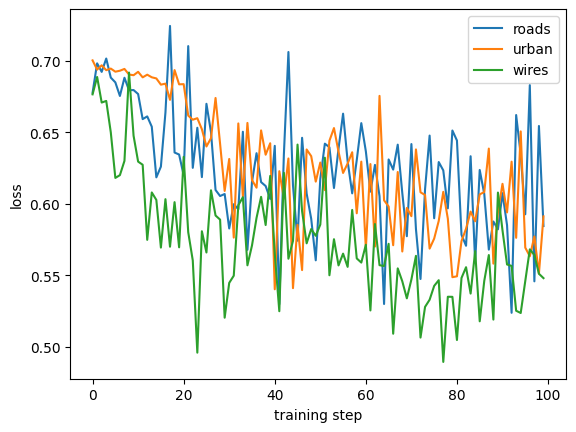

In [21]:
# ---- 1. orientation features for wires (8 dims) ----
def feat_vec(p, feat):
    p = p.astype(np.float32) / 255.0
    if feat == "orient":
        gy, gx = np.gradient(p); mag = np.hypot(gx, gy)
        ang = np.arctan2(gy, gx) % np.pi
        h, _ = np.histogram(ang, bins=7, range=(0, np.pi), weights=mag)
        return np.append(h / (h.sum() + 1e-6), min(mag.mean() * 10, 1.0))
    if feat == "edge":
        gy, gx = np.gradient(p); p = np.clip(np.hypot(gx, gy) * 4, 0, 1)
    small = Image.fromarray((p * 255).astype(np.uint8)).resize((16, 16), Image.BOX)
    return (np.array(small) / 255.0).ravel()

RAW["wires"] = make_dataset(files=tt_files[::20], loader=load_ttpla, patch=64,
                            thr=0.02, feat="orient", n_tr=200, n_te=100)
print("wires:", RAW["wires"][0].shape, RAW["wires"][2].shape)

# ---- 2. multi-seed run with steadier training ----
rows, curves = [], {}
for name, (Xtr, ytr, Xte, yte) in RAW.items():
    print(f"\n=== {name} ===")
    pca = PCA(8).fit(Xtr)
    sc = MinMaxScaler((0, np.pi)).fit(pca.transform(Xtr))
    Ftr = np.clip(sc.transform(pca.transform(Xtr)), 0, np.pi)
    Fte = np.clip(sc.transform(pca.transform(Xte)), 0, np.pi)

    accs, ptes = [], []
    for seed in range(3):
        ptr, pte, hist, nq = train_qcnn(Ftr, ytr, Fte, steps=100, bs=64, lr=0.05, seed=seed)
        accs.append(((pte > 0.5) == yte).mean()); ptes.append(pte)
        print(f"  seed {seed}: acc {accs[-1]:.3f}")
    curves[name] = hist

    best = int(np.argmax(accs)); pte = ptes[best]
    lr_acc = LogisticRegression(max_iter=1000).fit(Ftr, ytr).score(Fte, yte)
    mlp_acc = MLPClassifier((16,), max_iter=2000, random_state=0).fit(Ftr, ytr).score(Fte, yte)

    # decision support: flag the 20% least-confident patches for manual inspection
    conf = np.abs(pte - 0.5)
    flag = conf <= np.quantile(conf, 0.20)
    conf_acc = ((pte[~flag] > 0.5) == yte[~flag]).mean()

    rows.append({"task": name, "QCNN acc (mean±std)": f"{np.mean(accs):.3f}±{np.std(accs):.3f}",
                 "LogReg acc": round(lr_acc, 3), "MLP acc": round(mlp_acc, 3),
                 "QCNN params": nq, "MLP params": 161,
                 "acc on confident 80%": round(conf_acc, 3)})

results = pd.DataFrame(rows); print("\n"); display(results)
results.to_csv("results_v2.csv", index=False)
for k, h in curves.items(): plt.plot(h, label=k)
plt.xlabel("training step"); plt.ylabel("loss"); plt.legend(); plt.show()